# GAN on PET Images

This notebook adapts the original Fashion-MNIST GAN notebook to the **AutoPET** dataset.

Main changes:
- loads **PET NIfTI volumes** from `imagesTr`
- extracts 2D PET slices
- resizes slices to a fixed resolution
- uses a **convolutional GAN**
- includes **validation**
- includes **early stopping**
- restores the **best generator and discriminator weights**

In [1]:
import os
import glob
import random
import numpy as np
import matplotlib.pyplot as plt
import nibabel as nib
from sklearn.model_selection import train_test_split

import tensorflow as tf
from tensorflow.keras import Model, Input
from tensorflow.keras.layers import (
    Dense, Reshape, Flatten, Conv2D, Conv2DTranspose,
    LeakyReLU, Dropout, BatchNormalization, GaussianNoise
)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.losses import BinaryCrossentropy

print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices('GPU'))


I0000 00:00:1776170024.799179  392977 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1776170024.832071  392977 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


TensorFlow: 2.21.0
GPU devices: []


I0000 00:00:1776170025.588618  392977 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
W0000 00:00:1776170025.765977  392977 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


## Configuration

Update `DATA_ROOT` so it points to the folder that contains `imagesTr` and `labelsTr`.

This notebook assumes the common medical-imaging naming convention:
- `*_0000.nii.gz` = CT
- `*_0001.nii.gz` = PET

If your dataset uses the opposite order, change `PET_SUFFIX`.

In [2]:

DATA_ROOT = "/home/lina/Téléchargements/autopet/autopet"   # change if needed
IMAGES_DIR = os.path.join(DATA_ROOT, "imagesTr")
LABELS_DIR = os.path.join(DATA_ROOT, "labelsTr")

PET_SUFFIX = "_0001.nii.gz"   # AutoPET usually stores PET as _0001
TARGET_SIZE = (64, 64)
LATENT_DIM = 128

MAX_CASES = None              # set to an integer for faster experiments, e.g. 20
MAX_SLICES_PER_CASE = 32      # keeps training manageable
MIN_NONZERO_RATIO = 0.02      # skip almost-empty slices
MIN_ACTIVE_RATIO = 0.01       # skip slices with almost no PET activity after preprocessing
VAL_SIZE = 0.10

N_EPOCHS = 100
BATCH_SIZE = 32
LEARNING_RATE_G = 0.0002
LEARNING_RATE_D = 0.0001
BETA_1 = 0.5

EARLY_STOPPING_WARMUP = 15
EARLY_STOPPING_PATIENCE = 10
MIN_DELTA = 1e-4
BALANCE_WEIGHT = 0.10
INSTANCE_NOISE_START = 0.08
INSTANCE_NOISE_END = 0.0

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
random.seed(SEED)


In [3]:
assert os.path.isdir(IMAGES_DIR), f"imagesTr not found: {IMAGES_DIR}"

all_image_files = sorted(glob.glob(os.path.join(IMAGES_DIR, "*.nii.gz")))
pet_files = [f for f in all_image_files if f.endswith(PET_SUFFIX)]

if MAX_CASES is not None:
    pet_files = pet_files[:MAX_CASES]

print("Total files in imagesTr:", len(all_image_files))
print("PET files selected:", len(pet_files))
print("Example PET files:")
for f in pet_files[:5]:
    print(" -", os.path.basename(f))

Total files in imagesTr: 16
PET files selected: 8
Example PET files:
 - PETCT_0af7ffe12a_08-12-2005-NA-PET-CT Ganzkoerper  primaer mit KM-96698_0001.nii.gz
 - PETCT_0b57b247b6_05-02-2002-NA-PET-CT Ganzkoerper  primaer mit KM-42966_0001.nii.gz
 - PETCT_0b98dbe00d_08-11-2002-NA-PET-CT Ganzkoerper  primaer mit KM-83616_0001.nii.gz
 - PETCT_0beb67c923_07-25-1999-NA-PET-CT Ganzkoerper  primaer mit KM-37911_0001.nii.gz
 - PETCT_0c13e4df10_10-11-2003-NA-PET-CT Ganzkoerper  primaer mit KM-89759_0001.nii.gz


## Quick inspection of one PET volume

Sample file: PETCT_0af7ffe12a_08-12-2005-NA-PET-CT Ganzkoerper  primaer mit KM-96698_0001.nii.gz
Volume shape: (400, 400, 304)
Min: 0.0
Max: 74.66661071777344
Mean: 0.13157174982601536


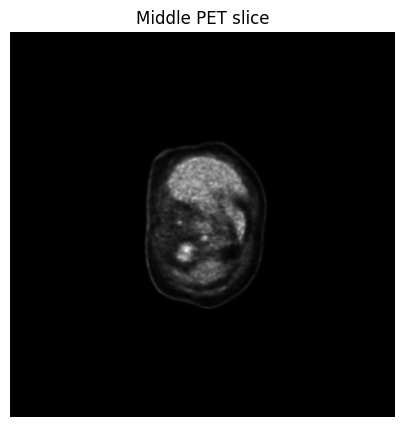

In [4]:
sample_path = pet_files[0]
sample_vol = nib.load(sample_path).get_fdata()

print("Sample file:", os.path.basename(sample_path))
print("Volume shape:", sample_vol.shape)
print("Min:", float(sample_vol.min()))
print("Max:", float(sample_vol.max()))
print("Mean:", float(sample_vol.mean()))

mid = sample_vol.shape[2] // 2
plt.figure(figsize=(5, 5))
plt.imshow(sample_vol[:, :, mid], cmap="gray")
plt.title("Middle PET slice")
plt.axis("off")
plt.show()

## Slice extraction and preprocessing

The GAN is trained on **2D PET slices** extracted from 3D volumes.

Preprocessing steps:
- keep only informative slices
- resize to `TARGET_SIZE`
- normalize each slice to `[-1, 1]`

In [5]:
def crop_to_foreground(slice_2d, threshold_ratio=0.08, margin=8):
    slice_2d = np.asarray(slice_2d, dtype=np.float32)
    if np.max(slice_2d) <= 0:
        return slice_2d

    thr = threshold_ratio * float(np.max(slice_2d))
    coords = np.argwhere(slice_2d > thr)

    if coords.size == 0:
        return slice_2d

    y0, x0 = coords.min(axis=0)
    y1, x1 = coords.max(axis=0) + 1

    y0 = max(0, y0 - margin)
    x0 = max(0, x0 - margin)
    y1 = min(slice_2d.shape[0], y1 + margin)
    x1 = min(slice_2d.shape[1], x1 + margin)

    return slice_2d[y0:y1, x0:x1]


def normalize_pet_slice(slice_2d):
    slice_2d = np.asarray(slice_2d, dtype=np.float32)
    slice_2d = np.maximum(slice_2d, 0.0)

    positive = slice_2d[slice_2d > 0]
    if positive.size == 0:
        return np.zeros_like(slice_2d, dtype=np.float32)

    # log compression makes PET uptake patterns easier to model
    slice_2d = np.log1p(slice_2d)

    positive = slice_2d[slice_2d > 0]
    low = np.percentile(positive, 1)
    high = np.percentile(positive, 99.5)
    slice_2d = np.clip(slice_2d, low, high)

    min_val = float(slice_2d.min())
    max_val = float(slice_2d.max())

    if max_val > min_val:
        slice_2d = (slice_2d - min_val) / (max_val - min_val)
    else:
        slice_2d = np.zeros_like(slice_2d, dtype=np.float32)

    slice_2d = slice_2d * 2.0 - 1.0
    return slice_2d.astype(np.float32)


def resize_slice(slice_2d, target_size=TARGET_SIZE):
    x = slice_2d[..., np.newaxis]
    x = tf.image.resize(x, target_size, method="bilinear").numpy()
    return x.astype(np.float32)


def extract_pet_slices_from_volume(volume, max_slices_per_case=MAX_SLICES_PER_CASE,
                                   min_nonzero_ratio=MIN_NONZERO_RATIO,
                                   min_active_ratio=MIN_ACTIVE_RATIO):
    kept = []

    for i in range(volume.shape[2]):
        sl = np.asarray(volume[:, :, i], dtype=np.float32)

        nonzero_ratio = np.count_nonzero(sl) / sl.size
        if nonzero_ratio < min_nonzero_ratio:
            continue

        sl = crop_to_foreground(sl, threshold_ratio=0.08, margin=8)
        sl = normalize_pet_slice(sl)

        # require some meaningful activity after normalization
        active_ratio = np.mean(sl > -0.3)
        if active_ratio < min_active_ratio:
            continue

        sl = resize_slice(sl)
        kept.append(sl)

    if len(kept) == 0:
        return []

    if len(kept) > max_slices_per_case:
        idx = np.linspace(0, len(kept) - 1, max_slices_per_case).astype(int)
        kept = [kept[j] for j in idx]

    return kept


def build_pet_dataset(file_list, max_slices_per_case=MAX_SLICES_PER_CASE):
    dataset = []

    for path in file_list:
        try:
            vol = nib.load(path).get_fdata()
            slices = extract_pet_slices_from_volume(
                vol,
                max_slices_per_case=max_slices_per_case,
                min_nonzero_ratio=MIN_NONZERO_RATIO,
                min_active_ratio=MIN_ACTIVE_RATIO
            )
            dataset.extend(slices)
        except Exception as e:
            print(f"Skipping {os.path.basename(path)} because of error: {e}")

    dataset = np.asarray(dataset, dtype=np.float32)
    return dataset


In [6]:
dataset = build_pet_dataset(pet_files)

print("Dataset shape:", dataset.shape)
print("Value range:", float(dataset.min()), "to", float(dataset.max()))

Dataset shape: (256, 64, 64, 1)
Value range: -1.0 to 1.0


## Visualize dataset samples

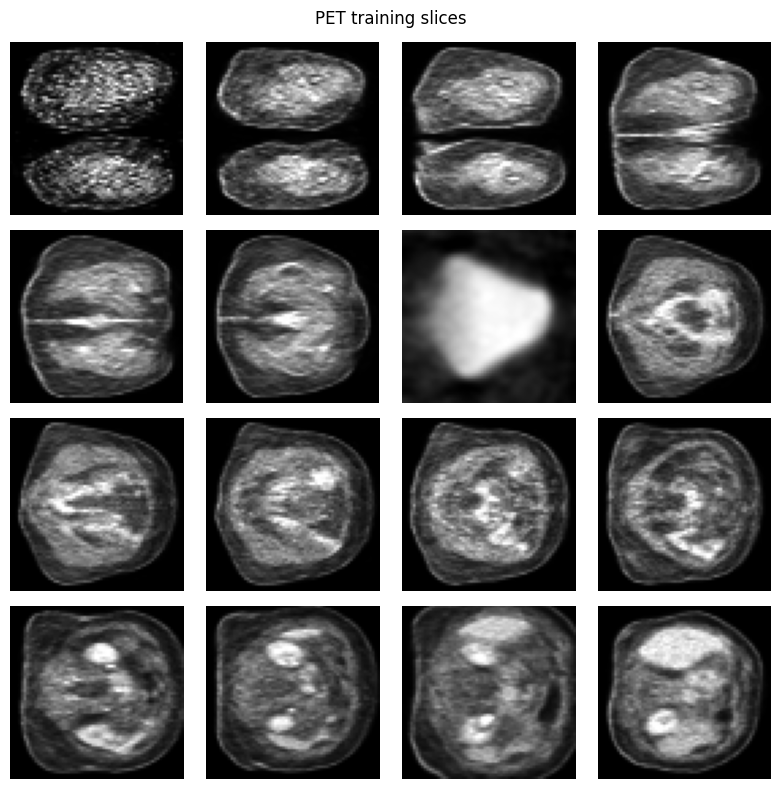

In [7]:
plt.figure(figsize=(8, 8))
for i in range(min(16, len(dataset))):
    plt.subplot(4, 4, i + 1)
    plt.imshow(dataset[i, :, :, 0], cmap="gray")
    plt.axis("off")
plt.suptitle("PET training slices")
plt.tight_layout()
plt.show()

## Train / validation split

In [8]:
trainX, valX = train_test_split(
    dataset,
    test_size=VAL_SIZE,
    random_state=SEED,
    shuffle=True
)

print("Train shape:", trainX.shape)
print("Validation shape:", valX.shape)

Train shape: (230, 64, 64, 1)
Validation shape: (26, 64, 64, 1)


## Discriminator

In [9]:
def define_discriminator(in_shape=(64, 64, 1), learning_rate=LEARNING_RATE_D):
    inp = Input(shape=in_shape)

    x = GaussianNoise(0.05)(inp)

    x = Conv2D(64, (4, 4), strides=(2, 2), padding="same")(x)
    x = LeakyReLU(0.2)(x)
    x = Dropout(0.25)(x)

    x = Conv2D(128, (4, 4), strides=(2, 2), padding="same")(x)
    x = LeakyReLU(0.2)(x)
    x = Dropout(0.25)(x)

    x = Conv2D(256, (4, 4), strides=(2, 2), padding="same")(x)
    x = LeakyReLU(0.2)(x)
    x = Dropout(0.25)(x)

    x = Conv2D(512, (4, 4), strides=(2, 2), padding="same")(x)
    x = LeakyReLU(0.2)(x)
    x = Dropout(0.25)(x)

    x = Flatten()(x)
    out = Dense(1)(x)   # logits

    model = Model(inp, out)
    opt = Adam(learning_rate=learning_rate, beta_1=BETA_1)
    model.compile(
        loss=BinaryCrossentropy(from_logits=True),
        optimizer=opt,
        metrics=["accuracy"]
    )
    return model


## Generator

In [10]:
def define_generator(latent_dim=LATENT_DIM, learning_rate=LEARNING_RATE_G):
    inp = Input(shape=(latent_dim,))

    x = Dense(4 * 4 * 512)(inp)
    x = Reshape((4, 4, 512))(x)

    x = Conv2DTranspose(256, (4, 4), strides=(2, 2), padding="same", use_bias=False)(x)
    x = BatchNormalization()(x)
    x = LeakyReLU(0.2)(x)

    x = Conv2DTranspose(128, (4, 4), strides=(2, 2), padding="same", use_bias=False)(x)
    x = BatchNormalization()(x)
    x = LeakyReLU(0.2)(x)

    x = Conv2DTranspose(64, (4, 4), strides=(2, 2), padding="same", use_bias=False)(x)
    x = BatchNormalization()(x)
    x = LeakyReLU(0.2)(x)

    x = Conv2DTranspose(32, (4, 4), strides=(2, 2), padding="same", use_bias=False)(x)
    x = BatchNormalization()(x)
    x = LeakyReLU(0.2)(x)

    out = Conv2D(1, (5, 5), activation="tanh", padding="same")(x)

    model = Model(inp, out)
    return model


## Combined GAN

In [11]:
def define_gan(generator, discriminator, learning_rate=LEARNING_RATE_G):
    discriminator.trainable = False
    out = discriminator(generator.output)
    model = Model(generator.input, out)
    opt = Adam(learning_rate=learning_rate, beta_1=BETA_1)
    model.compile(loss=BinaryCrossentropy(from_logits=True), optimizer=opt)
    return model


## Create models

In [12]:
d_model = define_discriminator(in_shape=(TARGET_SIZE[0], TARGET_SIZE[1], 1))
g_model = define_generator(latent_dim=LATENT_DIM)
gan_model = define_gan(g_model, d_model)

g_model.summary()
d_model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8192)           │     1,056,768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 4, 4, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 8, 8, 256)      │     2,097,152 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 8, 8, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_4 (LeakyReLU)       │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 16, 16, 128)    │       524,288 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_5 (LeakyReLU)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 32, 32, 64)     │       131,072 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_6 (LeakyReLU)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_3              │ (None, 64, 64, 32)     │        32,768 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_7 (LeakyReLU)       │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 64, 64, 1)      │           801 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,844,769 (14.67 MB)

 Trainable params: 3,843,809 (14.66 MB)

 Non-trainable params: 960 (3.75 KB)

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 64, 64, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gaussian_noise (GaussianNoise)  │ (None, 64, 64, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 64)     │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 128)    │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 256)      │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 4, 4, 512)      │     2,097,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 4, 4, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 4, 4, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         8,193 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,762,689 (10.54 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 2,762,689 (10.54 MB)

## Helper functions

In [13]:
def add_instance_noise(x, stddev):
    if stddev <= 0:
        return x
    noise = np.random.normal(0.0, stddev, size=x.shape).astype(np.float32)
    x_noisy = x + noise
    return np.clip(x_noisy, -1.0, 1.0)


def generate_real_samples(dataset, n, real_label_value=0.9):
    ix = np.random.randint(0, dataset.shape[0], n)
    X = dataset[ix]
    y = np.ones((n, 1), dtype=np.float32) * real_label_value
    return X, y


def generate_latent_points(latent_dim, n):
    return np.random.randn(latent_dim * n).reshape(n, latent_dim).astype(np.float32)


def generate_fake_samples(generator, latent_dim, n):
    z_input = generate_latent_points(latent_dim, n)
    images = generator.predict(z_input, verbose=0)
    y = np.zeros((n, 1), dtype=np.float32)
    return images, y


## Fixed validation inputs for stable monitoring

In [14]:
FIXED_NOISE = generate_latent_points(LATENT_DIM, 25)
VAL_MONITOR_SIZE = min(len(valX), 128)

if VAL_MONITOR_SIZE < len(valX):
    val_monitor_idx = np.random.choice(len(valX), size=VAL_MONITOR_SIZE, replace=False)
    VAL_FIXED = valX[val_monitor_idx]
else:
    VAL_FIXED = valX.copy()

print("Fixed validation set shape:", VAL_FIXED.shape)
print("Fixed noise shape:", FIXED_NOISE.shape)

Fixed validation set shape: (26, 64, 64, 1)
Fixed noise shape: (25, 128)


## Visualization helpers

In [15]:
def show_generated(examples, n=25, title="Generated Images"):
    examples = (examples + 1.0) / 2.0
    examples = np.clip(examples, 0.0, 1.0)

    side = int(np.sqrt(n))
    plt.figure(figsize=(8, 8))
    for i in range(n):
        plt.subplot(side, side, i + 1)
        plt.imshow(examples[i, :, :, 0], cmap="gray")
        plt.axis("off")
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()


def summarize_performance(epoch, generator, fixed_noise=FIXED_NOISE, n_samples=25):
    images = generator.predict(fixed_noise[:n_samples], verbose=0)
    show_generated(images, n=n_samples, title=f"Generated PET slices at epoch {epoch}")

## Training loop with validation and early stopping

In [30]:
def train_gan(
    g_model,
    d_model,
    gan_model,
    train_data,
    val_data,
    latent_dim=LATENT_DIM,
    n_epochs=N_EPOCHS,
    n_batch=BATCH_SIZE,
    summarize_every=10,
    warmup=EARLY_STOPPING_WARMUP,
    patience=EARLY_STOPPING_PATIENCE,
    min_delta=MIN_DELTA,
    balance_weight=BALANCE_WEIGHT
):
    bat_per_epo = train_data.shape[0] // n_batch
    half_batch = n_batch // 2

    history = {
        "d_real_train": [],
        "d_fake_train": [],
        "g_train": [],
        "d_real_val": [],
        "d_fake_val": [],
        "g_val": [],
        "es_score": [],
        "g_img_std": []
    }

    best_score = np.inf
    best_epoch = -1
    stopped_epoch = None
    wait = 0
    best_g_weights = None
    best_d_weights = None

    for epoch in range(n_epochs):
        d_real_epoch = []
        d_fake_epoch = []
        g_epoch = []

        if n_epochs > 1:
            noise_std = INSTANCE_NOISE_START + (INSTANCE_NOISE_END - INSTANCE_NOISE_START) * (epoch / (n_epochs - 1))
        else:
            noise_std = INSTANCE_NOISE_END

        for _ in range(bat_per_epo):
            X_real, y_real = generate_real_samples(train_data, half_batch, real_label_value=0.9)
            X_fake, y_fake = generate_fake_samples(g_model, latent_dim, half_batch)

            X_real_noisy = add_instance_noise(X_real, noise_std)
            X_fake_noisy = add_instance_noise(X_fake, noise_std)

            d_loss_real, _ = d_model.train_on_batch(X_real_noisy, y_real)
            d_loss_fake, _ = d_model.train_on_batch(X_fake_noisy, y_fake)

            z_input = generate_latent_points(latent_dim, n_batch)
            y_gan = np.ones((n_batch, 1), dtype=np.float32) * 0.9
            g_loss = gan_model.train_on_batch(z_input, y_gan)

            d_real_epoch.append(float(d_loss_real))
            d_fake_epoch.append(float(d_loss_fake))
            g_epoch.append(float(g_loss))

        history["d_real_train"].append(np.mean(d_real_epoch))
        history["d_fake_train"].append(np.mean(d_fake_epoch))
        history["g_train"].append(np.mean(g_epoch))

        y_real_val = np.ones((VAL_FIXED.shape[0], 1), dtype=np.float32) * 0.9
        val_real_noisy = add_instance_noise(VAL_FIXED, noise_std * 0.5)
        d_real_val, _ = d_model.evaluate(val_real_noisy, y_real_val, verbose=0)

        fake_val = g_model.predict(FIXED_NOISE[:VAL_FIXED.shape[0]], verbose=0)
        g_img_std = float(np.std(fake_val))

        val_fake_noisy = add_instance_noise(fake_val, noise_std * 0.5)
        y_fake_val = np.zeros((fake_val.shape[0], 1), dtype=np.float32)
        d_fake_val, _ = d_model.evaluate(val_fake_noisy, y_fake_val, verbose=0)

        y_val_gan = np.ones((FIXED_NOISE.shape[0], 1), dtype=np.float32) * 0.9
        g_val = gan_model.evaluate(FIXED_NOISE, y_val_gan, verbose=0)

        es_score = float(g_val + balance_weight * abs(d_real_val - d_fake_val))

        history["d_real_val"].append(float(d_real_val))
        history["d_fake_val"].append(float(d_fake_val))
        history["g_val"].append(float(g_val))
        history["es_score"].append(es_score)
        history["g_img_std"].append(g_img_std)

        print(
            f"Epoch {epoch + 1}/{n_epochs} | "
            f"d_real_train={history['d_real_train'][-1]:.4f}, "
            f"d_fake_train={history['d_fake_train'][-1]:.4f}, "
            f"g_train={history['g_train'][-1]:.4f} | "
            f"d_real_val={d_real_val:.4f}, "
            f"d_fake_val={d_fake_val:.4f}, "
            f"g_val={g_val:.4f}, "
            f"es_score={es_score:.4f}, "
            f"g_img_std={g_img_std:.4f}, "
            f"noise_std={noise_std:.4f}"
        )

        # Always track best score from the beginning
        improved = es_score < best_score - min_delta

        if improved:
            best_score = es_score
            best_epoch = epoch + 1
            best_g_weights = g_model.get_weights()
            best_d_weights = d_model.get_weights()

            # Only reset patience after warmup
            if epoch + 1 > warmup:
                wait = 0
        else:
            # Only count patience after warmup
            if epoch + 1 > warmup:
                wait += 1

        # Only allow stopping after warmup
        if epoch + 1 > warmup and wait >= patience:
            stopped_epoch = epoch + 1
            print(f"Early stopping triggered at epoch {stopped_epoch}. Restoring best weights from epoch {best_epoch}.")
            if best_g_weights is not None:
                g_model.set_weights(best_g_weights)
            if best_d_weights is not None:
                d_model.set_weights(best_d_weights)
            break

        if (epoch + 1) % summarize_every == 0:
            summarize_performance(epoch + 1, g_model, fixed_noise=FIXED_NOISE)

    return history, best_epoch, stopped_epoch

## Train the GAN

Epoch 1/80 | d_real_train=1.0337, d_fake_train=1.0580, g_train=0.4217 | d_real_val=0.7083, d_fake_val=1.3542, g_val=0.4015, es_score=0.7244, g_img_std=0.9602, noise_std=0.0800
Epoch 2/80 | d_real_train=1.0282, d_fake_train=1.0526, g_train=0.4226 | d_real_val=0.7085, d_fake_val=1.3552, g_val=0.4013, es_score=0.7246, g_img_std=0.9599, noise_std=0.0790
Epoch 3/80 | d_real_train=1.0325, d_fake_train=1.0578, g_train=0.4230 | d_real_val=0.7084, d_fake_val=1.3563, g_val=0.4011, es_score=0.7250, g_img_std=0.9597, noise_std=0.0780
Epoch 4/80 | d_real_train=1.0309, d_fake_train=1.0554, g_train=0.4211 | d_real_val=0.7084, d_fake_val=1.3573, g_val=0.4009, es_score=0.7254, g_img_std=0.9594, noise_std=0.0770
Epoch 5/80 | d_real_train=1.0315, d_fake_train=1.0561, g_train=0.4213 | d_real_val=0.7083, d_fake_val=1.3554, g_val=0.4013, es_score=0.7249, g_img_std=0.9598, noise_std=0.0759
Epoch 6/80 | d_real_train=1.0315, d_fake_train=1.0563, g_train=0.4212 | d_real_val=0.7084, d_fake_val=1.3560, g_val=0.40

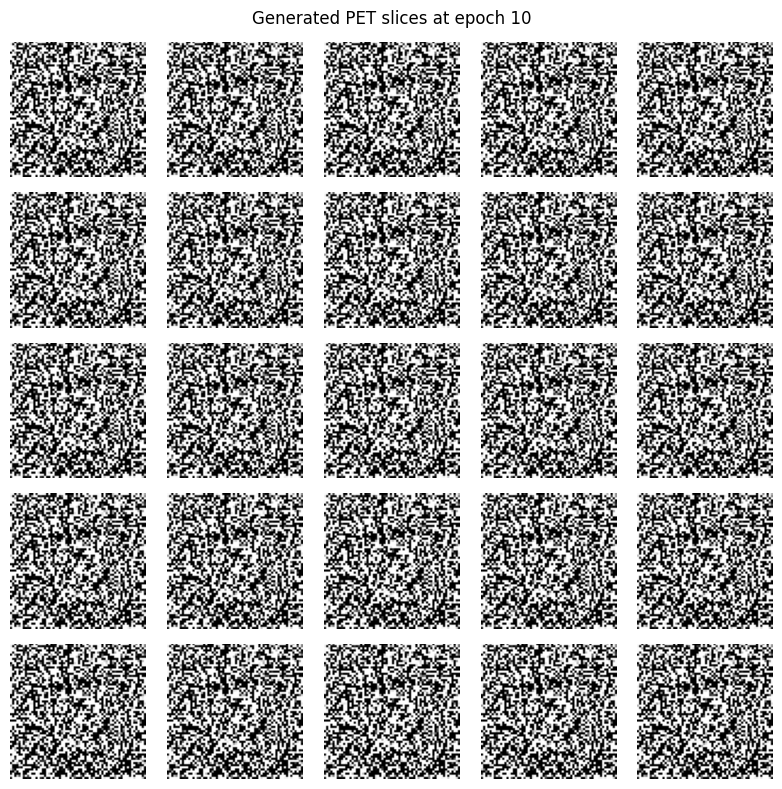

Epoch 11/80 | d_real_train=1.0328, d_fake_train=1.0576, g_train=0.4213 | d_real_val=0.7085, d_fake_val=1.3588, g_val=0.4008, es_score=0.7260, g_img_std=0.9595, noise_std=0.0699
Epoch 12/80 | d_real_train=1.0324, d_fake_train=1.0567, g_train=0.4214 | d_real_val=0.7085, d_fake_val=1.3593, g_val=0.4008, es_score=0.7262, g_img_std=0.9595, noise_std=0.0689
Epoch 13/80 | d_real_train=1.0329, d_fake_train=1.0578, g_train=0.4216 | d_real_val=0.7083, d_fake_val=1.3601, g_val=0.4006, es_score=0.7265, g_img_std=0.9591, noise_std=0.0678
Epoch 14/80 | d_real_train=1.0336, d_fake_train=1.0584, g_train=0.4211 | d_real_val=0.7084, d_fake_val=1.3600, g_val=0.4007, es_score=0.7264, g_img_std=0.9586, noise_std=0.0668
Epoch 15/80 | d_real_train=1.0344, d_fake_train=1.0592, g_train=0.4211 | d_real_val=0.7083, d_fake_val=1.3601, g_val=0.4007, es_score=0.7266, g_img_std=0.9590, noise_std=0.0658
Epoch 16/80 | d_real_train=1.0342, d_fake_train=1.0593, g_train=0.4202 | d_real_val=0.7085, d_fake_val=1.3632, g_va

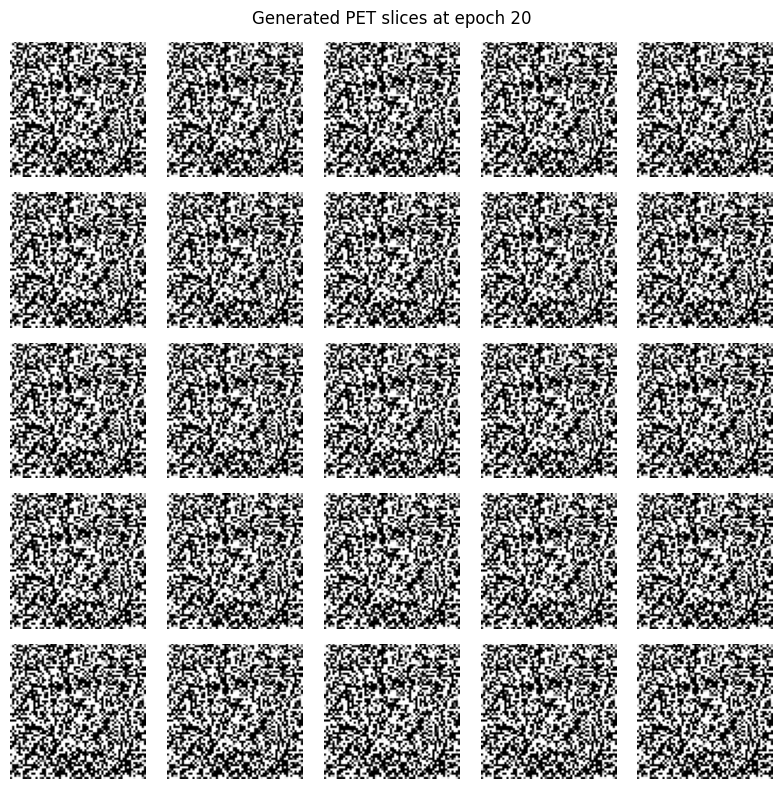

Epoch 21/80 | d_real_train=1.0368, d_fake_train=1.0617, g_train=0.4204 | d_real_val=0.7084, d_fake_val=1.3633, g_val=0.4003, es_score=0.7277, g_img_std=0.9596, noise_std=0.0597
Epoch 22/80 | d_real_train=1.0346, d_fake_train=1.0597, g_train=0.4219 | d_real_val=0.7084, d_fake_val=1.3640, g_val=0.4001, es_score=0.7279, g_img_std=0.9599, noise_std=0.0587
Epoch 23/80 | d_real_train=1.0337, d_fake_train=1.0584, g_train=0.4213 | d_real_val=0.7083, d_fake_val=1.3652, g_val=0.3999, es_score=0.7284, g_img_std=0.9588, noise_std=0.0577
Epoch 24/80 | d_real_train=1.0358, d_fake_train=1.0608, g_train=0.4205 | d_real_val=0.7084, d_fake_val=1.3649, g_val=0.4000, es_score=0.7283, g_img_std=0.9590, noise_std=0.0567
Epoch 25/80 | d_real_train=1.0346, d_fake_train=1.0594, g_train=0.4212 | d_real_val=0.7085, d_fake_val=1.3669, g_val=0.3997, es_score=0.7289, g_img_std=0.9586, noise_std=0.0557
Epoch 26/80 | d_real_train=1.0333, d_fake_train=1.0573, g_train=0.4213 | d_real_val=0.7085, d_fake_val=1.3662, g_va

In [32]:
history, best_epoch, stopped_epoch = train_gan(
    g_model,
    d_model,
    gan_model,
    trainX,
    valX,
    latent_dim=LATENT_DIM,
    n_epochs=80,
    n_batch=BATCH_SIZE,
    summarize_every=10,
    warmup=20,
    patience=10,
    min_delta=0.002,
    balance_weight=0.5
)

## Plot losses

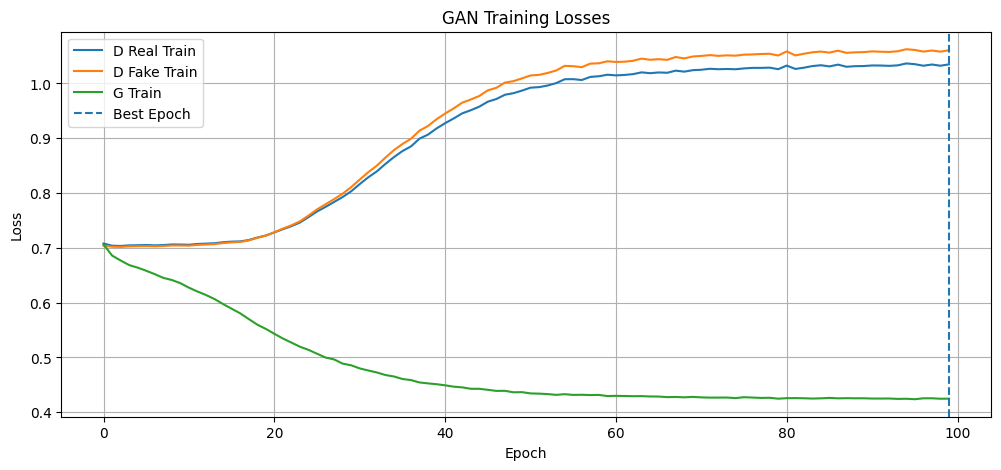

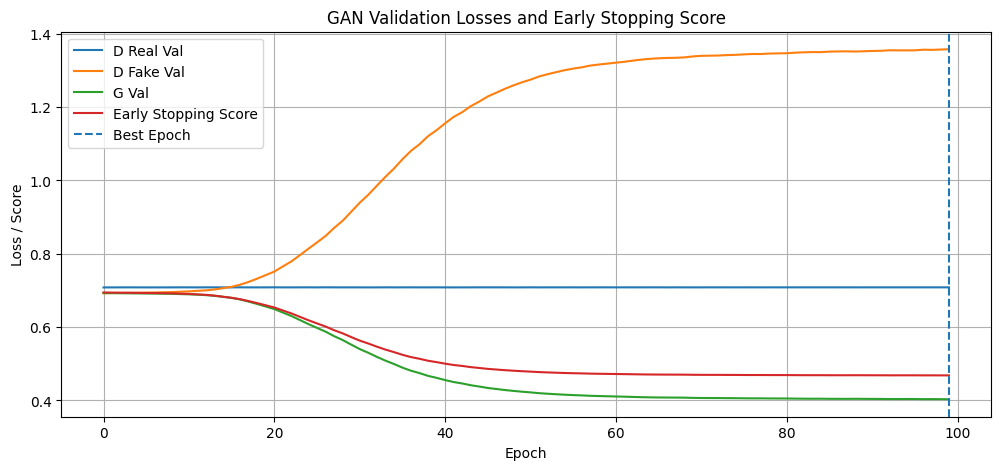

In [18]:
plt.figure(figsize=(12, 5))
plt.plot(history["d_real_train"], label="D Real Train")
plt.plot(history["d_fake_train"], label="D Fake Train")
plt.plot(history["g_train"], label="G Train")
if best_epoch != -1:
    plt.axvline(best_epoch - 1, linestyle="--", label="Best Epoch")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("GAN Training Losses")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(12, 5))
plt.plot(history["d_real_val"], label="D Real Val")
plt.plot(history["d_fake_val"], label="D Fake Val")
plt.plot(history["g_val"], label="G Val")
plt.plot(history["es_score"], label="Early Stopping Score")
if best_epoch != -1:
    plt.axvline(best_epoch - 1, linestyle="--", label="Best Epoch")
plt.xlabel("Epoch")
plt.ylabel("Loss / Score")
plt.title("GAN Validation Losses and Early Stopping Score")
plt.legend()
plt.grid(True)
plt.show()

## Generate images after training

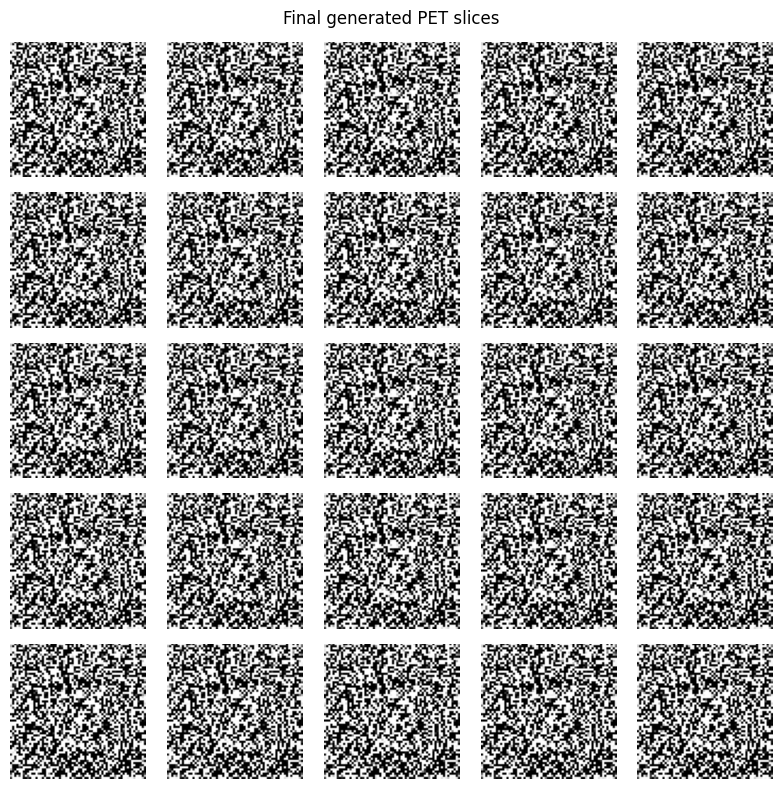

In [19]:
generated_images = g_model.predict(FIXED_NOISE, verbose=0)
show_generated(generated_images, n=25, title="Final generated PET slices")

## Save the trained generator

In [20]:
model_name = "gan_generator_autopet_pet.keras"
g_model.save(model_name)
print(f"Generator saved successfully as {model_name}")

Generator saved successfully as gan_generator_autopet_pet.keras


## Save one generated image grid

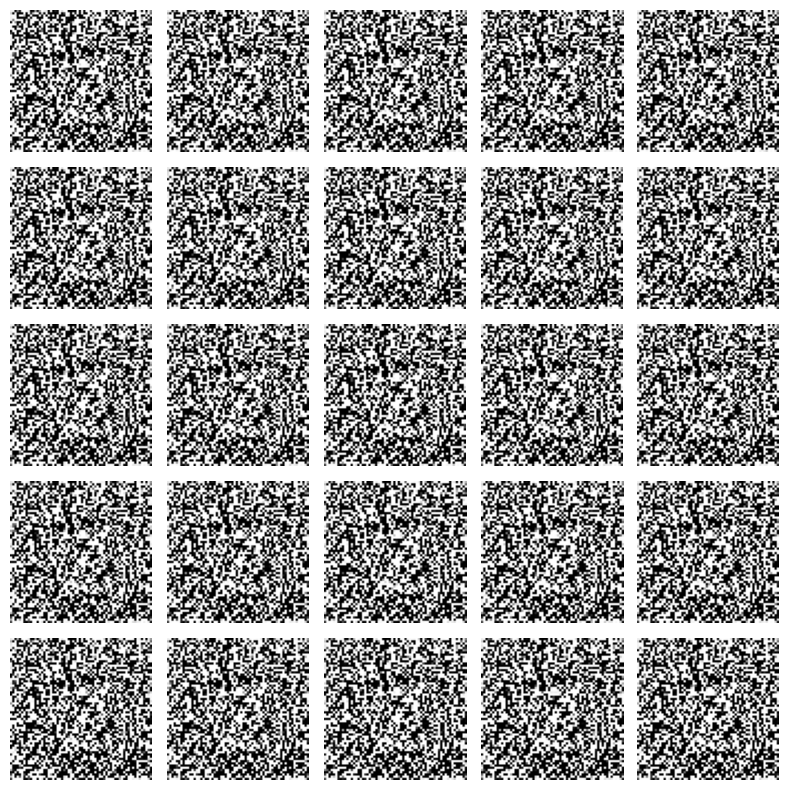

Saved generated image grid as gan_autopet_generated_grid.png


In [21]:
generated_images = g_model.predict(FIXED_NOISE, verbose=0)
generated_images = (generated_images + 1.0) / 2.0
generated_images = np.clip(generated_images, 0.0, 1.0)

plt.figure(figsize=(8, 8))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.imshow(generated_images[i, :, :, 0], cmap="gray")
    plt.axis("off")
plt.tight_layout()
plt.savefig("gan_autopet_generated_grid.png", dpi=200, bbox_inches="tight")
plt.show()

print("Saved generated image grid as gan_autopet_generated_grid.png")